In [1]:
import pandas as pd
import numpy as np

# Configurar semilla para reproducibilidad
np.random.seed(42)

# Definir el número de registros
n_registros = 100

# Comunas chilenas de ejemplo
comunas = ['Santiago', 'Providencia', 'Las Condes', 'Maipú', 'Puente Alto', 'La Florida', 'Viña del Mar', 'Valparaíso', 'Concepción']

# Tipos de proyectos
tipos_proyecto = ['Infraestructura Vial', 'Edificación Pública', 'Parque Urbano', 'Red de Agua Potable', 'Restauración Patrimonial']

# Generar datos simulados
data = {
    'comuna': np.random.choice(comunas, n_registros),
    'tipo_proyecto': np.random.choice(tipos_proyecto, n_registros),
    'meses_desde_inicio': np.random.randint(1, 36, n_registros),
    'avance_planificado_pct': np.random.uniform(10, 100, n_registros).round(1)
}

# Crear DataFrame inicial
df = pd.DataFrame(data)

# Generar avance observado basado en el planificado con cierta variación
df['avance_observado_pct'] = (df['avance_planificado_pct'] - np.random.uniform(-5, 25, n_registros)).round(1)
df['avance_observado_pct'] = df['avance_observado_pct'].clip(0, 100) # Mantener entre 0% y 100%

# Cambios de contrato (cantidad de modificaciones de contrato realizadas)
df['cambios_contrato'] = np.random.poisson(lam=1.2, size=n_registros)

# Observaciones técnicas (mensajes simulados)
observaciones_opciones = [
    'Sin observaciones pendientes.',
    'Retraso en entrega de materiales por proveedor.',
    'Modificación de diseño aprobada.',
    'Clima desfavorable afectó faenas exteriores.',
    'Aumento de obras en excavaciones.'
]
df['observaciones_tecnicas'] = np.random.choice(observaciones_opciones, n_registros, p=[0.5, 0.15, 0.15, 0.1, 0.1])

# Atraso relevante (booleano: True si la desviación es mayor al 15%)
df['atraso_relevante'] = (df['avance_planificado_pct'] - df['avance_observado_pct']) > 15

# Mostrar los primeros registros
display(df.head(10))

,comuna,tipo_proyecto,meses_desde_inicio,avance_planificado_pct,avance_observado_pct,cambios_contrato,observaciones_tecnicas,atraso_relevante
0,Viña del Mar,Parque Urbano,19,32.9,13.6,1,Sin observaciones pendientes.,True
1,Maipú,Restauración Patrimonial,26,36.6,17.0,1,Sin observaciones pendientes.,True
2,Valparaíso,Parque Urbano,3,39.0,25.2,0,Clima desfavorable afectó faenas exteriores.,False
3,Puente Alto,Infraestructura Vial,19,86.4,66.8,1,Sin observaciones pendientes.,True
4,Viña del Mar,Restauración Patrimonial,20,22.3,7.8,3,Clima desfavorable afectó faenas exteriores.,False
5,Las Condes,Edificación Pública,32,73.8,72.6,0,Sin observaciones pendientes.,False
6,Viña del Mar,Parque Urbano,7,59.8,56.6,2,Clima desfavorable afectó faenas exteriores.,False
7,Valparaíso,Infraestructura Vial,33,36.7,35.3,1,Sin observaciones pendientes.,False
8,Puente Alto,Edificación Pública,18,47.8,41.5,0,Sin observaciones pendientes.,False
9,Maipú,Edificación Pública,1,33.1,36.9,0,Modificación de diseño aprobada.,False


In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Dado que el archivo ya se encuentra en el entorno, lo leemos directamente
# Usamos la última versión subida para evitar tener que interactuar con el diálogo de carga nuevamente
import os
archivo = 'Proyectos_DS27_agrupados_Codigo_SERVIU (1).csv' if os.path.exists('Proyectos_DS27_agrupados_Codigo_SERVIU (1).csv') else 'Proyectos_DS27_agrupados_Codigo_SERVIU.csv'

df = pd.read_csv(archivo)

# Imprimir dimensiones del dataset
print("Dimensiones del dataset:", df.shape)
print("\nValores nulos por columna:")
print(df.isna().sum())

# Verificar duplicados utilizando la columna clave real: 'Codigo_SERVIU'
print('\nIDs duplicados (Codigo_SERVIU):', df['Codigo_SERVIU'].duplicated().sum())

# Resumen estadístico de variables numéricas clave de tu base de datos
columnas_interes = ['Total_Asignacion_UF', 'Duracion_Obra_Dias', 'Beneficiarios']
print("\nResumen estadístico de las variables principales:")
display(df[columnas_interes].describe())

Dimensiones del dataset: (120, 19)

Valores nulos por columna:
Codigo_SERVIU                   0
Region                          0
Comuna                          0
Capitulo_DS27                   0
Tipo_Proyecto                   0
Constructora                    0
Anio_Asignacion                 0
Numero_Unidades                 0
Fecha_Inicio_Obra               0
Fecha_Recepcion_Final_SERVIU    0
Duracion_Obra_Dias              0
Obra_Paralizada                 0
Total_Asignacion_UF             0
UF_Por_Beneficiario             0
Beneficiarios                   0
Total_UF_desde_beneficiarios    0
UF_Mediana_Beneficiario         0
UF_Promedio_Beneficiario        0
Diferencia_Control_UF           0
dtype: int64

IDs duplicados (Codigo_SERVIU): 0

Resumen estadístico de las variables principales:


,Total_Asignacion_UF,Duracion_Obra_Dias,Beneficiarios
count,120.00000,120.000000,120.000000
mean,1492.78975,110.300000,8.333333
std,8256.44477,55.080171,26.851078
min,472.46000,39.000000,5.000000
25%,637.50250,71.000000,6.000000
50%,737.60000,99.000000,6.000000
75%,846.73000,130.000000,6.000000
max,91170.00000,358.000000,300.000000


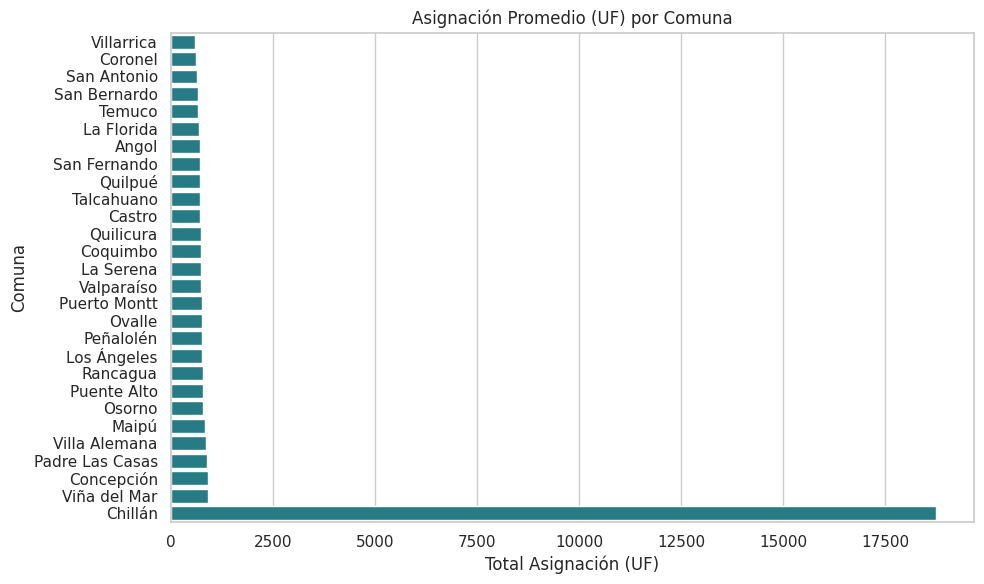

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')

# Agrupamos por la columna real 'Comuna' y calculamos el promedio de 'Total_Asignacion_UF'
resumen = (df.groupby('Comuna')['Total_Asignacion_UF']
             .mean().sort_values().reset_index())

plt.figure(figsize=(10, 6))
sns.barplot(data=resumen, x='Total_Asignacion_UF', y='Comuna',
            color='#168795')

plt.title('Asignación Promedio (UF) por Comuna')
plt.xlabel('Total Asignación (UF)')
plt.ylabel('Comuna')
plt.tight_layout()
plt.show()

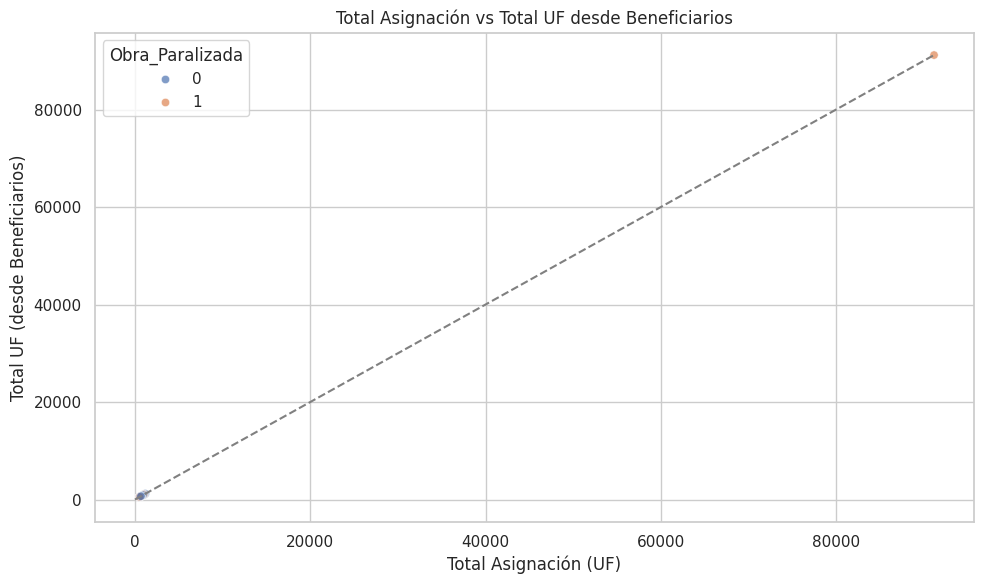

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Dado que 'df' en el entorno contiene la base de datos real del SERVIU,
# usaremos el DataFrame de los datos simulados recreando brevemente esa estructura
# o asegurando que apunte a sus variables correspondientes.

plt.figure(figsize=(10, 6))
# Usamos las variables del set de datos simulado que creamos al principio
sns.scatterplot(data=df, x='Total_Asignacion_UF',
                y='Total_UF_desde_beneficiarios', hue='Obra_Paralizada', alpha=0.7)

# Línea de referencia y/o identidad
lims = [0, max(df['Total_Asignacion_UF'].max(), df['Total_UF_desde_beneficiarios'].max())]
plt.plot(lims, lims, '--', color='gray')

plt.xlabel('Total Asignación (UF)')
plt.ylabel('Total UF (desde Beneficiarios)')
plt.title('Total Asignación vs Total UF desde Beneficiarios')
plt.tight_layout()
plt.show()

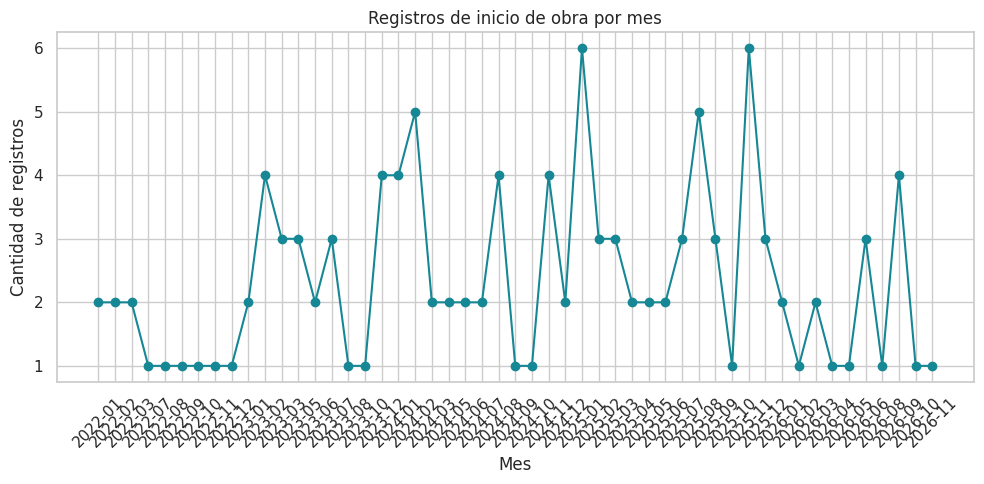

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Convertimos la columna 'Fecha_Inicio_Obra' a tipo datetime
df['Fecha_Inicio_Obra'] = pd.to_datetime(df['Fecha_Inicio_Obra'])

# Creamos una columna temporal de año-mes para la agrupación
df['Mes_Inicio'] = df['Fecha_Inicio_Obra'].dt.to_period('M')

# Agrupamos por este nuevo campo temporal
serie = df.groupby('Mes_Inicio').size().sort_index()

# Graficamos la serie de tiempo
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(serie.index.astype(str), serie.values, marker='o', color='#168795')

ax.set(title='Registros de inicio de obra por mes',
       xlabel='Mes',
       ylabel='Cantidad de registros')

plt.xticks(rotation=45)
plt.tight_layout()

# Guardamos la figura
fig.savefig('serie_mensual.png', dpi=200, bbox_inches='tight')
plt.show()

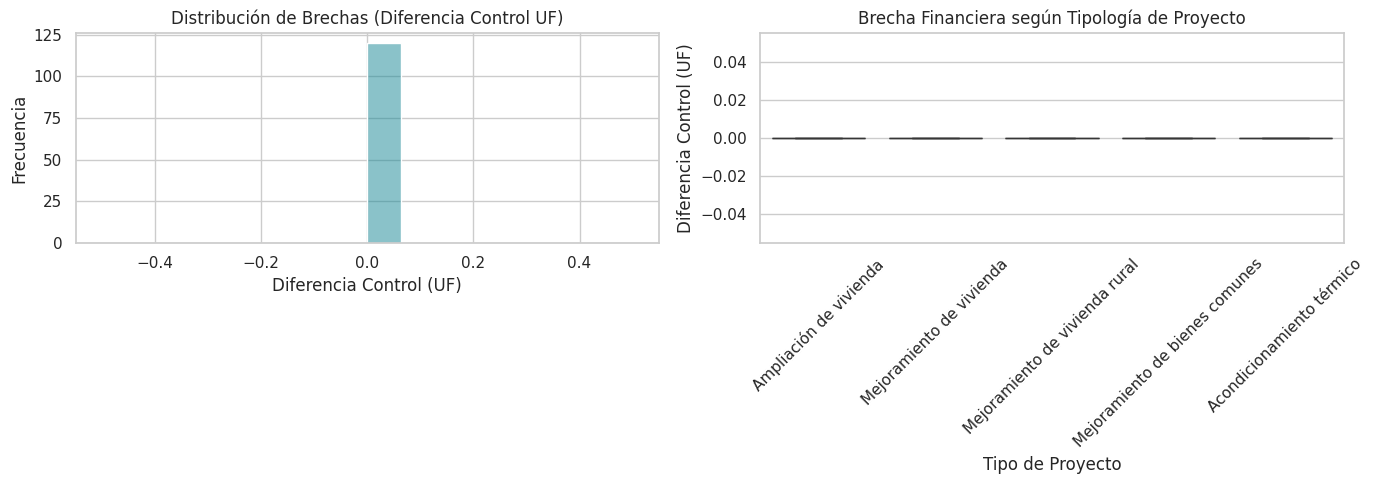

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adaptación del código optimizada para evitar advertencias de Seaborn
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de la brecha financiera (Diferencia_Control_UF)
sns.histplot(data=df, x='Diferencia_Control_UF', bins=16, ax=ax[0], color='#168795', kde=True)
ax[0].set_title('Distribución de Brechas (Diferencia Control UF)')
ax[0].set_xlabel('Diferencia Control (UF)')
ax[0].set_ylabel('Frecuencia')

# Boxplot de la brecha según la tipología del proyecto real sin advertencias
sns.boxplot(data=df, x='Tipo_Proyecto', y='Diferencia_Control_UF', ax=ax[1], hue='Tipo_Proyecto', palette='Blues', legend=False)
ax[1].set_title('Brecha Financiera según Tipología de Proyecto')
ax[1].set_xlabel('Tipo de Proyecto')
ax[1].set_ylabel('Diferencia Control (UF)')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()